# Session 5 — Ensembles: when more models help

Session 4 fitted three kinds of model and compared them one against another. This session asks a
different question: **is one model ever enough?** Instead of choosing the best single model, we build
many models and combine their answers into one.

The idea is old and it is not obvious. Adding models costs fitting time, prediction time, memory and
readability. This session shows what you get back, and — on our data — what you do not.

## Learning objectives

By the end of this session you will be able to:

1. Explain the one condition under which combining models helps: they must be **wrong in different
   ways**.
2. Describe **bagging** as a way to cut the variance of an unstable model, and read an **out-of-bag**
   estimate.
3. Explain what a **random forest** adds to bagging, and why its feature importances must be read
   with care.
4. Describe **boosting** as fitting each new model to what the previous ones got wrong, and explain
   the trade between the **learning rate** and the **number of trees**.
5. Use **early stopping** to choose the number of trees on a validation set rather than on the test
   set.
6. Compare every candidate against a baseline and against a simple model, and say honestly when the
   difference is smaller than the noise.
7. Weigh an ensemble's accuracy against what it costs in fitting time, prediction time and size.

## How the session is organized

We stay on the **churn data from session 4**, so that every number here can be compared against the
models you already fitted. The ensembles are introduced in the order that builds on itself: voting,
then bagging, then random forests, then boosting, then stacking. The session closes by measuring what
the ensembles cost, and by re-running the whole comparison on a second dataset, where the answer
changes.

> **What you need from earlier sessions.** Decision trees and the classification metrics come from
> session 4. Cross-validation, the split lottery and the idea of **variance** come from session 3.
> The preparation pipeline comes from session 2. Nothing here is tuned: every setting is chosen by
> hand and said to be. **Session 6** searches for settings properly.

The cell below imports everything the notebook uses and fixes one random seed, reused by every later
cell so that the numbers quoted in this text reproduce:

In [ ]:
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

RANDOM_STATE = 42

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier

## The Data

The dataset is the one from session 4: **Telco customer churn**, `data/telco_churn.csv`, 7,043
customers of a telecommunications company described by 20 features, with the target `Churn` — whether
the customer cancelled the service. About **26.5%** of them left, so the classes are imbalanced but
not rare.

Session 4 established three things about this data that we reuse without repeating:

- `TotalCharges` arrives as text, because eleven brand-new customers have a blank there. Those blanks
  mean **zero**, not "unknown".
- The split must be **stratified**, so that both halves keep the same share of churners.
- Accuracy is the wrong headline measure here. We rank models by **ROC AUC**, which measures how well
  a model **ranks** churners above stayers, independently of any threshold.

The cell below loads the file and repeats that cleaning in one step. It prints the shape and the
share of churners, which should match session 4's 0.2654:

In [21]:
churn = pd.read_csv("data/telco_churn.csv").drop(columns="customerID")
churn["TotalCharges"] = pd.to_numeric(churn["TotalCharges"], errors="coerce").fillna(0.0)
churn["Churn"] = (churn["Churn"] == "Yes").astype(int)

print(f"{churn.shape[0]} rows x {churn.shape[1]} columns")
print(f"positive class rate: {churn['Churn'].mean():.4f}")

7043 rows x 20 columns
positive class rate: 0.2654


The cell below splits the data, builds the same preparation recipe as session 4 — scale the three
numeric columns, one-hot encode the sixteen text ones — and defines a helper that chains it to any
model. It prints the width of the prepared matrix:

In [22]:
X = churn.drop(columns="Churn")
y = churn["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

NUMERIC_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL_COLS = [column for column in X.columns if column not in NUMERIC_COLS]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUMERIC_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False),
         CATEGORICAL_COLS),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")


def make_model(estimator) -> Pipeline:
    """Chain the shared preprocessing recipe to an estimator.

    Args:
        estimator: Any scikit-learn classifier.

    Returns:
        A pipeline that prepares the columns and then applies the estimator.
    """
    return Pipeline([("prep", preprocessor), ("model", estimator)])


print(f"training rows: {len(X_train)}   test rows: {len(X_test)}")
print(f"prepared matrix: {preprocessor.fit_transform(X_train).shape[1]} columns")

training rows: 5282   test rows: 1761
prepared matrix: 40 columns


### The numbers to beat

Every ensemble in this session has to be compared against something. We rebuild session 4's
candidates first: the baseline that always answers "stayed", logistic regression, a tree of depth 4
and KNN with $k = 25$.

One thing changes from session 4. There, every model was scored on a single test set, and the wrap-up
said that this leaves each number carrying the split lottery. Here we use **5-fold cross-validation on
the training data**, as session 3 did, so that each score arrives with a spread. The test set is not
touched until the end.

The cell below scores the four models. Read the mean, then the standard deviation beside it — it says
how much the mean would move on a different split:

In [24]:
# TODO: add input data as an argument to the function
def cv_auc(estimator, label: str) -> dict:
    """Cross-validate one estimator on the training data and report ROC AUC.

    Args:
        estimator: Any scikit-learn classifier, without preprocessing.
        label: Name to report the result under.

    Returns:
        The label, the mean ROC AUC across folds and its standard deviation.
    """
    scores = cross_val_score(
        make_model(estimator), X_train, y_train, cv=5, scoring="roc_auc", n_jobs=-1
    )
    return {"model": label, "CV AUC": scores.mean(), "sd": scores.std()}


results = [
    cv_auc(DummyClassifier(strategy="most_frequent"), "Baseline (always 'stayed')"),
    cv_auc(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), "Logistic regression"),
    cv_auc(DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE), "Decision tree (depth 4)"),
    cv_auc(KNeighborsClassifier(n_neighbors=25), "KNN (k=25)"),
]
pd.DataFrame(results).round(4)

,model,CV AUC,sd
0,Baseline (always 'stayed'),0.5000,0.0000
1,Logistic regression,0.8438,0.0130
2,Decision tree (depth 4),0.8257,0.0115
3,KNN (k=25),0.8290,0.0137


**Logistic regression leads with a cross-validated AUC of 0.8438**, ahead of KNN (0.8290) and the
shallow tree (0.8257). The baseline sits at exactly 0.5000, which is what "no ranking ability at all"
looks like on this measure.

Note the spread: about **0.013** for each real model. Session 3's rule applies for the rest of this
session — **a gap smaller than that is not a finding**. Logistic regression's lead over KNN (0.015) is
about the size of one standard deviation, so even that is weak evidence.

This is the number every ensemble below must beat: **0.8438**.

## Why combining models can help

Suppose three models each answer the same question, and each is wrong about a quarter of the time.
If you take the answer the majority gives, you are wrong only when **two of the three are wrong at
once**. How often that happens depends entirely on whether they make the same mistakes.

- If the three models are wrong about **the same customers**, the majority is wrong about exactly
  those customers. Combining them changes nothing.
- If they are wrong about **different customers**, a mistake by one is outvoted by the other two, and
  the combination is better than any single model.

So the whole of ensemble learning rests on one condition: **the models must be wrong in different
ways**. Everything in this session is a different strategy for producing models that disagree.

The simplest strategy is to use different kinds of model, and the simplest way to combine them is a
**vote**:

- **Hard voting** — each model predicts a class, and the majority class wins.
- **Soft voting** — each model predicts a probability, and the probabilities are averaged. This
  usually works better, because a model that is unsure contributes less than one that is certain.

> **In `scikit-learn`.** `VotingClassifier(estimators=[...], voting="soft")`. The estimators are
> named, as pipeline steps are, and each one is fitted on the whole training set.

The cell below builds a soft vote of the three session-4 models and cross-validates it:

In [25]:
voting_members = [
    ("lr", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ("tree", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)),
    ("knn", KNeighborsClassifier(n_neighbors=25)),
]

In [26]:
voting_results = cv_auc(
    VotingClassifier(voting_members, voting="soft"), "Soft vote (LR + tree + KNN)"
)

In [27]:
results.append(voting_results)
pd.DataFrame(results).round(4)

,model,CV AUC,sd
0,Baseline (always 'stayed'),0.5000,0.0000
1,Logistic regression,0.8438,0.0130
2,Decision tree (depth 4),0.8257,0.0115
3,KNN (k=25),0.8290,0.0137
4,Soft vote (LR + tree + KNN),0.8434,0.0127


**The vote scores 0.8434, and logistic regression alone scored 0.8438.** Combining three models
bought nothing at all.

That is the first honest result of the session, and it is worth sitting with. The vote did not fail
because voting is a bad idea. It failed because **the three members are not wrong in different enough
ways** — they were all fitted on the same 40 columns, and they all mostly follow `tenure`, `Contract`
and the charges. Two weak members also drag the average down: the tree sits 0.018 below logistic
regression and KNN 0.015 below it, and soft voting gives all three an equal say.

The rest of the session builds models that disagree **on purpose**.

## Bagging: many models from one dataset

If disagreement is what we need, one way to get it is to fit the same kind of model to **different
data**. We have only one dataset, so we manufacture variety from it.

A **bootstrap sample** is a new dataset of the same size, drawn from the original **with
replacement**: some rows appear twice or three times, and others do not appear at all. Each bootstrap
sample is a slightly different version of the same data.

**Bagging** — short for *bootstrap aggregating* — is then three steps:

1. Draw $B$ bootstrap samples from the training data.
2. Fit one model, called a **base learner**, on each sample.
3. Average their predicted probabilities.

Averaging is what does the work. If the $B$ models were completely independent and each had variance
$\sigma^2$, the variance of their average would be:

$$\operatorname{Var}\left(\frac{1}{B}\sum_{b=1}^{B} f_b(x)\right) = \frac{\sigma^2}{B}$$

where:

- $B$ — the number of models in the ensemble, a whole number of 1 or more.
- $f_b(x)$ — the prediction of the $b$-th model for the row $x$.
- $\sigma^2$ — the variance of one model's prediction: how much it moves when the training data
  changes. It is 0 or more.

In practice the models are **not** independent, because their bootstrap samples overlap, so the
reduction is smaller than $B$ says. The direction is still right, and it points at which base learner
to use: bagging helps most when the base learner has **high variance** — when small changes in the
data change its predictions a lot. That is exactly what an unrestricted decision tree does.

The cell below fits a deep tree — no depth limit at all — on five different bootstrap samples, and
reports for each one its ROC AUC on the test set and how many leaves it grew. Then it counts how
often pairs of these trees give a different answer about the same customer:

In [28]:
X_train_preproc = preprocessor.fit_transform(X_train)
X_test_preproc = preprocessor.transform(X_test)

generator = np.random.default_rng(RANDOM_STATE)
bootstrap_predictions = []
for number in range(5):
    rows = generator.choice(len(X_train_preproc), len(X_train_preproc), replace=True)
    tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
    tree.fit(X_train_preproc.iloc[rows], y_train.iloc[rows])
    bootstrap_predictions.append(tree.predict(X_test_preproc))
    area = roc_auc_score(y_test, tree.predict_proba(X_test_preproc)[:, 1])
    print(f"tree {number + 1}: test AUC {area:.4f}, {tree.get_n_leaves()} leaves")

disagreements = [
    np.mean(bootstrap_predictions[first] != bootstrap_predictions[second])
    for first in range(5)
    for second in range(first + 1, 5)
]
print()
print(f"pairs of trees that disagree about a customer: {np.mean(disagreements):.1%} on average")

tree 1: test AUC 0.6540, 698 leaves
tree 2: test AUC 0.6561, 663 leaves
tree 3: test AUC 0.6580, 665 leaves
tree 4: test AUC 0.6553, 685 leaves
tree 5: test AUC 0.6293, 665 leaves

pairs of trees that disagree about a customer: 25.5% on average


**Each tree grew between 663 and 698 leaves, and scores between 0.63 and 0.66** — far below the depth-4 tree's
0.8257. An unrestricted tree keeps splitting until its leaves are almost pure, which memorises the
training data.

**The five trees disagree about 25.5% of test customers.** They saw almost the same data and produced
noticeably different models. That instability is the variance session 3 measured, here in its most
extreme form — and it is exactly the raw material bagging needs.

The cell below fits 200 such trees on 200 bootstrap samples and averages them:

In [29]:
results.append(cv_auc(DecisionTreeClassifier(random_state=RANDOM_STATE), "Deep tree (no limit)"))

In [30]:
bagging_clf = cv_auc(
    BaggingClassifier(
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Bagged deep trees (200)",
)

In [31]:
results.append(bagging_clf)
pd.DataFrame(results).round(4)

,model,CV AUC,sd
0,Baseline (always 'stayed'),0.5000,0.0000
1,Logistic regression,0.8438,0.0130
2,Decision tree (depth 4),0.8257,0.0115
3,KNN (k=25),0.8290,0.0137
4,Soft vote (LR + tree + KNN),0.8434,0.0127
5,Deep tree (no limit),0.6594,0.0164
6,Bagged deep trees (200),0.8190,0.0123


**One deep tree scores 0.6594. Two hundred of them, averaged, score 0.8190.**

Nothing about the base learner changed. The same memorising tree, fitted 200 times on 200 slightly
different datasets and averaged, gains **0.16 of AUC**. This is the clearest demonstration in the
course that *how you use a model* can matter more than *which model you use*.

It still does not beat logistic regression's 0.8438, and it does not beat the plain depth-4 tree's
0.8257 either. Bagging repaired the deep tree; it did not turn it into the best model available.

### Out-of-bag error: an estimate that costs nothing

A bootstrap sample leaves out roughly a third of the rows — those that happened not to be drawn. For
each row, the models that never saw it can predict it, and those predictions are honest, because for
those models the row is unseen data.

Averaging that over all rows gives the **out-of-bag (OOB) score**: an estimate of performance on
unseen data that needs no separate validation split and no extra fitting.

> **In `scikit-learn`.** `BaggingClassifier(..., oob_score=True)` stores it in `oob_score_`. It is an
> accuracy, not an AUC. `RandomForestClassifier` has the same option.

The cell below fits a bagged ensemble with the option switched on and prints its out-of-bag score next
to its accuracy on the real test set. The two should be close:

In [32]:
bagged = make_model(
    BaggingClassifier(
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=200,
        oob_score=True,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
)
bagged.fit(X_train, y_train)

print(f"out-of-bag accuracy: {bagged.named_steps['model'].oob_score_:.4f}")
print(f"test accuracy:       {bagged.score(X_test, y_test):.4f}")

out-of-bag accuracy: 0.7863
test accuracy:       0.7831


**Out-of-bag 0.7863 against a test accuracy of 0.7831** — a gap of 0.003, well inside the spread we
measured for cross-validation. The free estimate is as good as the one we paid for.

This matters when data is scarce. Cross-validation refits the model five times; the out-of-bag score
comes out of a single fit, because the bootstrap has already built the held-out sets for you.

## Random forests: forcing the trees apart

Bagging's trees still agree more than we would like. They are all fitted on the same columns, so
whenever one feature is much stronger than the rest, almost every tree splits on it first and the
trees end up similar. On this data `tenure`, `Contract` and the charges dominate, so the bootstrap
alone cannot make the trees very different.

A **random forest** adds a second source of difference: at **every split**, the tree may only choose
from a random subset of the features. A tree that is denied `tenure` at its root is forced to find a
different question, and so it makes different mistakes.

> **In `scikit-learn`.** `RandomForestClassifier(n_estimators=..., max_features=...)`.
> `max_features="sqrt"` — the square root of the number of columns — is the default for
> classification. Setting `max_features=None` turns the forest back into plain bagging of trees.

The cell below fits a forest of 300 trees and cross-validates it, so that it can be compared with the
bagged trees directly:

In [ ]:
rf_results = cv_auc(
    RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1,
        max_features="sqrt",
        # bootstrap=True,
        # max_samples=None
        # max_depth=None
        
    ),
    "Random forest (300)",
)

In [34]:
results.append(rf_results)
pd.DataFrame(results).round(4)

,model,CV AUC,sd
0,Baseline (always 'stayed'),0.5000,0.0000
1,Logistic regression,0.8438,0.0130
2,Decision tree (depth 4),0.8257,0.0115
3,KNN (k=25),0.8290,0.0137
4,Soft vote (LR + tree + KNN),0.8434,0.0127
5,Deep tree (no limit),0.6594,0.0164
6,Bagged deep trees (200),0.8190,0.0123
7,Random forest (300),0.8246,0.0143


**The forest reaches 0.8246 against bagging's 0.8190** — an improvement of 0.006, which is smaller
than the 0.013 spread. On this dataset, forcing the trees apart with random feature subsets did
**not** produce a measurable gain. On data with many mildly useful features it usually does; here a
few features carry almost everything, so the trees stay similar whatever we do.

Both are still below logistic regression.

### What the forest says is important

A forest of 300 trees cannot be read the way session 4 read a single depth-2 tree. What it can offer
instead is a ranking: for each feature, how much the splits that used it reduced impurity, averaged
over every tree. This is the **impurity-based feature importance**.

The cell below fits one forest and draws its ten highest-ranked features:

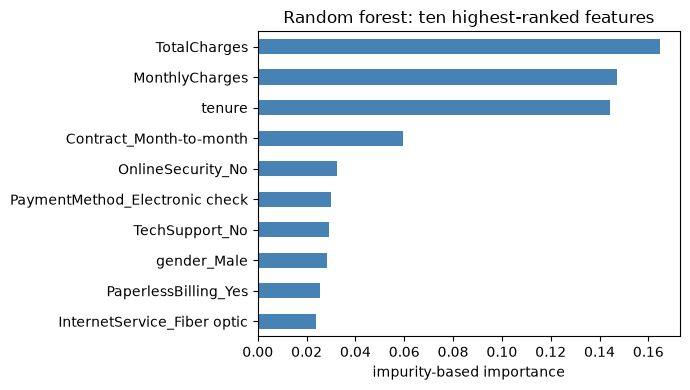

TotalCharges                      0.1647
MonthlyCharges                    0.1473
tenure                            0.1442
Contract_Month-to-month           0.0594
OnlineSecurity_No                 0.0324
PaymentMethod_Electronic check    0.0301
TechSupport_No                    0.0292
gender_Male                       0.0282
PaperlessBilling_Yes              0.0257
InternetService_Fiber optic       0.0238


In [35]:
forest = make_model(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
forest.fit(X_train, y_train)

importances = pd.Series(
    forest.named_steps["model"].feature_importances_,
    index=forest.named_steps["prep"].get_feature_names_out(),
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
importances.head(10).iloc[::-1].plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("impurity-based importance")
ax.set_title("Random forest: ten highest-ranked features")
fig.tight_layout()
plt.show()

print(importances.head(10).round(4).to_string())

The top three are `TotalCharges` (0.165), `MonthlyCharges` (0.147) and `tenure` (0.144), then
`Contract_Month-to-month` (0.059). That agrees with session 4: how long somebody has been a customer
and what they pay is most of the story.

**Now read the eighth row.** `gender_Male` scores 0.0282 — above `PaperlessBilling_Yes` and above
`InternetService_Fiber optic`, both of which describe what the customer actually buys. Gender is very
unlikely to drive churn in this dataset, and a ranking that puts it there should stop you.

The explanation is in how the measure is built. Impurity-based importance **favours features that
offer many possible split points**. A continuous column like `TotalCharges` offers thousands; a yes/no
column offers one. Randomness does the rest: a useless feature that is split on by chance still gets
credit for the small impurity drop that follows.

**So treat this ranking as a hint, never as evidence.** Session 7 takes the question up properly, with
a measure that does not have this bias.

## Boosting: each model fixes what the last one missed

Bagging fits its models **in parallel** and averages them. Every model sees the same problem and
tries to solve all of it.

**Boosting** goes the other way. Models are fitted **one after another**, and each new one works on
what the ensemble so far still gets wrong. The prediction is built up step by step:

$$F_m(x) = F_{m-1}(x) + \nu \, h_m(x)$$

where:

- $F_m(x)$ — the ensemble's prediction for row $x$ after $m$ steps.
- $h_m(x)$ — the model added at step $m$, fitted to the error that $F_{m-1}$ still makes. In gradient
  boosting it is a small tree.
- $\nu$ — the **learning rate**, between 0 and 1. It shrinks each new model's contribution.
- $m$ — the step number, from 1 up to the number of trees.

Two consequences follow, and both matter in practice:

- **The base learner should be weak, not strong.** Each tree only has to nudge the answer, so
  boosting uses shallow trees — depth 3 is typical. Bagging wants the opposite: strong, unstable
  models to average.
- **More trees is not always better.** Bagging cannot overfit by adding models: averaging more of
  them just stabilises the answer. Boosting **can**, because every new tree deliberately chases the
  remaining errors, and eventually those errors are noise.

The learning rate and the number of trees pull against each other. A small $\nu$ means each step moves
a little, so more steps are needed; a large $\nu$ reaches a good answer in few steps but can overshoot
and then degrade.

The cell below fits gradient boosting with 500 trees and, after every tree, measures the AUC on the
data it is fitted on and on a **validation set** — a slice held out of the training data, not the test
set. Watch where the two curves separate:

In [ ]:
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)
X_fit_preproc = preprocessor.fit_transform(X_fit)
X_validation_preproc = preprocessor.transform(X_validation)
X_test_from_fit = preprocessor.transform(X_test)

boosted = GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, random_state=RANDOM_STATE)
boosted.fit(X_fit_preproc, y_fit)

fit_curve = np.array([roc_auc_score(y_fit, s) for s in boosted.staged_decision_function(X_fit_preproc)])
validation_curve = np.array(
    [roc_auc_score(y_validation, s) for s in boosted.staged_decision_function(X_validation_preproc)]
)
best_round = int(validation_curve.argmax())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, 501), fit_curve, label="training data", linewidth=2)
ax.plot(range(1, 501), validation_curve, label="validation data", linewidth=2)
ax.axvline(best_round + 1, color="black", linestyle=":", label=f"validation peak ({best_round + 1} trees)")
ax.set_xlabel("number of trees")
ax.set_ylabel("ROC AUC")
ax.set_title("Boosting improves the training score long after it stops helping")
ax.legend()
fig.tight_layout()
plt.show()

print(f"validation peaks at {validation_curve[best_round]:.4f} with {best_round + 1} trees")
print(f"at 500 trees: training {fit_curve[-1]:.4f}, validation {validation_curve[-1]:.4f}")

**The two curves tell opposite stories.** On the training data the score climbs to **0.9584** and is
still climbing at 500 trees. On the validation data it peaks at **0.8587 after 45 trees** and then
falls away to **0.8374**.

Everything after tree 45 is the ensemble learning the training set's noise. A model that reports its
training score here would claim 0.96 while getting worse.

This is session 3's lesson in a new place: **the training score cannot tell you when to stop.**

### Early stopping

**Early stopping** is the fix, and it is exactly what the picture suggests: keep adding trees while a
held-out score improves, and stop when it stops improving.

The set you watch matters. It must not be the test set — choosing the number of trees by the test
score is selecting on the test set, the failure session 3 exists to prevent. It is a **validation**
set, taken out of the training data, exactly as above.

The cell below shows what that choice was worth. It reports the test AUC of the boosted ensemble
stopped at its validation peak, and the test AUC of the same ensemble run to all 500 trees:

In [ ]:
test_curve = np.array(
    [roc_auc_score(y_test, s) for s in boosted.staged_decision_function(X_test_from_fit)]
)

print(f"stopped at the validation peak ({best_round + 1} trees): test AUC {test_curve[best_round]:.4f}")
print(f"run to the end (500 trees):                 test AUC {test_curve[-1]:.4f}")

**0.8470 against 0.8275.** Stopping at the point the validation set chose is worth about 0.02 of AUC
here, and it also gives an ensemble eleven times smaller.

Note what we did **not** do: we never looked at the test curve to pick the number. The peak came from
the validation set, and the test set only confirmed the choice afterwards.

### The learning rate and the number of trees

The learning rate decides how big each step is, so it decides how many steps are needed. The cell
below fits the same ensemble at three learning rates and reports where the validation score peaks:

In [ ]:
rows = []
for rate in [0.01, 0.1, 0.5]:
    candidate = GradientBoostingClassifier(
        n_estimators=400, learning_rate=rate, random_state=RANDOM_STATE
    )
    candidate.fit(X_fit_preproc, y_fit)
    curve = np.array(
        [roc_auc_score(y_validation, s) for s in candidate.staged_decision_function(X_validation_preproc)]
    )
    rows.append(
        {
            "learning rate": rate,
            "best validation AUC": curve.max(),
            "trees needed": int(curve.argmax()) + 1,
            "AUC at 400 trees": curve[-1],
        }
    )

pd.DataFrame(rows).round(4)

Read the last two columns together.

- **At 0.01** the ensemble needs **395 trees** to reach 0.8571, and it is still at its best at 400. It
  learns slowly and safely.
- **At 0.1** it reaches a slightly better **0.8587 in 45 trees** — nine times fewer — then decays to
  0.8407 by tree 400.
- **At 0.5** it peaks after **12 trees** at 0.8557, then collapses to 0.8087. Each step is so large
  that the ensemble overshoots and starts fitting noise almost immediately.

**A small learning rate with many trees and a large one with few trees are two ways to spend the same
budget.** The first is usually safer and slower to fit. Choosing between them by hand, as we just did,
is what session 6 automates.

## XGBoost

**XGBoost** is a separate library that implements gradient boosting with a different engine. The idea
is the one above; what it adds is engineering and control:

- it grows the trees in a way that uses all processor cores, and handles missing values internally;
- it adds **regularization** — the same idea as in session 3's Ridge, a penalty that discourages
  complex trees;
- it stops early for you, given a validation set to watch.

> **In `scikit-learn`'s style.** `XGBClassifier` follows the same `fit` / `predict` / `predict_proba`
> contract, so it drops into a pipeline unchanged. `early_stopping_rounds=30` means "stop when the
> watched score has not improved for 30 rounds"; the set to watch is passed as `eval_set`.

The cell below gives it 1,000 trees and the same validation set, and lets it stop itself:

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=4,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric="auc",
    early_stopping_rounds=30,
)
xgb_model.fit(X_fit_preproc, y_fit, eval_set=[(X_validation_preproc, y_validation)], verbose=False)

print(f"trees kept: {xgb_model.best_iteration + 1} of 1000")
print(f"validation AUC: {xgb_model.best_score:.4f}")
print(f"test AUC:       {roc_auc_score(y_test, xgb_model.predict_proba(X_test_from_fit)[:, 1]):.4f}")

**XGBoost stopped itself after 70 trees**, with a validation AUC of 0.8565 and a test AUC of 0.8458 —
in the same region as scikit-learn's gradient boosting, which reached 0.8470 on the test set with 45
trees.

The two libraries agree, which is the useful result. XGBoost's reputation comes from competitions
where the data is larger and every setting has been tuned. Here, with both untuned, it is not the
better tool — it is the same tool.

## Stacking: learning how to combine

Voting weights every member equally. **Stacking** learns the weights instead: it fits the members,
then fits a further model — the **meta-model** — whose inputs are the members' predictions and whose
target is the true class.

The subtlety is which predictions the meta-model is trained on. If the members predicted the rows they
were fitted on, an overfitted member would look perfect and the meta-model would trust it completely.
So the members' predictions are produced by cross-validation, on rows each member did not see.

> **In `scikit-learn`.** `StackingClassifier(estimators=[...], final_estimator=..., cv=5)`. The `cv`
> argument is what produces the honest inner predictions. A simple `final_estimator` — a logistic
> regression — is the usual choice, because it only has to learn how much to trust each member.

The cell below stacks the three session-4 models under a logistic regression meta-model:

In [ ]:
results.append(
    cv_auc(
        StackingClassifier(
            estimators=voting_members,
            final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
            cv=5,
            n_jobs=-1,
        ),
        "Stacking (LR meta-model)",
    )
)
pd.DataFrame(results).round(4)

**Stacking reaches 0.8451 where the equal-weight vote reached 0.8434.** Learning the weights recovered
most of what the vote lost by giving the two weaker members an equal say — and it is the first
combination in this session to edge past logistic regression's 0.8438.

By 0.0013. The spread is 0.013. **That is not a finding**, and the next section says so properly.

## The honest comparison

Every candidate has now been cross-validated on the same folds. The cell below adds the boosted models
with the number of trees chosen on the validation set, and puts the whole table in order:

In [ ]:
results.append(
    cv_auc(
        GradientBoostingClassifier(
            n_estimators=best_round + 1, learning_rate=0.1, random_state=RANDOM_STATE
        ),
        f"Gradient boosting ({best_round + 1} trees)",
    )
)
results.append(
    cv_auc(
        XGBClassifier(
            n_estimators=xgb_model.best_iteration + 1,
            learning_rate=0.1,
            max_depth=4,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            eval_metric="logloss",
        ),
        "XGBoost (early stopped)",
    )
)

comparison = pd.DataFrame(results).sort_values("CV AUC", ascending=False).reset_index(drop=True)
comparison.round(4)

The cell below draws the same table, with each mean as a point and its spread as a bar, so that
"better" and "indistinguishable" can be told apart by eye:

In [ ]:
ordered = comparison[comparison["model"] != "Baseline (always 'stayed')"].iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(ordered["CV AUC"], ordered["model"], xerr=ordered["sd"], fmt="o", capsize=4, color="steelblue")
ax.axvline(
    comparison.loc[comparison["model"] == "Logistic regression", "CV AUC"].iloc[0],
    color="crimson", linestyle="--", linewidth=1, label="logistic regression",
)
ax.set_xlabel("cross-validated ROC AUC (bars: one standard deviation)")
ax.set_title("Ten candidates on the churn data")
ax.legend()
fig.tight_layout()
plt.show()

**The bars overlap almost everywhere.** Gradient boosting leads at 0.8464, then stacking 0.8451,
XGBoost 0.8443, logistic regression 0.8438 and the vote 0.8434. The whole group sits inside **0.003**,
against a spread of **0.013** per model.

The honest report is therefore not "gradient boosting won". It is:

> On this dataset, four ensembles and a logistic regression could not be told apart, and everything
> that could be told apart — the bagged trees, the forest, the shallow tree, KNN — was **worse**.

That result is the point of the session, and it is not a disappointment. Churn here is mostly driven
by a few features that act in a simple, additive way: a short contract, a high bill, few months with
the company. That is precisely the shape a linear model is built for, so there is little left for an
ensemble to find.

**Never present a sophisticated method as inherently better.** Which model wins is a property of the
dataset, and the only way to know is to measure.

## What an ensemble costs

Accuracy is one column of the decision. The cell below fits five of the candidates on the full
training set and measures three more: how long the fit takes, how long it takes to predict the 1,761
test customers, and how many kilobytes the fitted model occupies. The two timing columns change
from run to run and from machine to machine, so read their **order of magnitude**, not their digits;
the size column is exact:

In [ ]:
cost_candidates = {
    "Logistic regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "KNN (k=25)": KNeighborsClassifier(n_neighbors=25),
    "Random forest (300)": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    f"Gradient boosting ({best_round + 1} trees)": GradientBoostingClassifier(
        n_estimators=best_round + 1, learning_rate=0.1, random_state=RANDOM_STATE
    ),
}

rows = []
for name, estimator in cost_candidates.items():
    model = make_model(estimator)
    started = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - started

    started = time.perf_counter()
    probabilities = model.predict_proba(X_test)[:, 1]
    predict_ms = (time.perf_counter() - started) * 1000

    rows.append(
        {
            "model": name,
            "test AUC": roc_auc_score(y_test, probabilities),
            "fit (s)": fit_seconds,
            "predict (ms)": predict_ms,
            "size (KB)": len(pickle.dumps(model)) / 1024,
        }
    )

pd.DataFrame(rows).round(3)

Read the last column first. **Logistic regression occupies about 6 KB. The random forest occupies
about 50,000 KB** — roughly 50 MB, or nine thousand times more, for a worse AUC. It stores 300 trees,
and each tree stores every split it learned.

The other two columns matter in different situations. KNN's prediction time is the longest, because it
finds neighbours at prediction time rather than at fitting time — an unpleasant surprise if the model
has to answer a website in milliseconds. Bagging and forests are slow to fit but embarrassingly
parallel; boosting is sequential, so it cannot be spread across cores the same way.

And the column that does not appear in the table: **a single depth-4 tree can be read aloud to a
manager.** Three hundred of them cannot. Session 7 is about recovering some of what is lost there.

## Does the answer change on other data?

Everything above is one dataset. The claim this course keeps making is that **which model wins is a
property of the dataset**, so the comparison has to be run somewhere else before it means anything.

We re-run it on the **Ames housing** data from sessions 2 and 3: 1,460 houses, 79 features, and a
target that is a price rather than a class. The metric changes with the task — **RMSE**, the
root-mean-square error in dollars, where lower is better — but the candidates are the same families:
a linear model, one tree, a forest, boosting.

The cell below prepares Ames and cross-validates the four. Compare their order against the order on
churn:

In [ ]:
ames = pd.read_csv("data/ames_housing.csv")
ames_y = ames["SalePrice"]
ames_X = ames.drop(columns=[column for column in ["SalePrice", "Id"] if column in ames.columns])

ames_numeric = ames_X.select_dtypes("number").columns.tolist()
ames_categorical = [column for column in ames_X.columns if column not in ames_numeric]
ames_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
         ames_numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
         ames_categorical),
    ]
)

ames_rows = []
for name, estimator in {
    "Ridge regression": Ridge(alpha=10),
    "Decision tree (depth 4)": DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE),
    "Random forest (300)": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient boosting (200)": GradientBoostingRegressor(n_estimators=200, random_state=RANDOM_STATE),
}.items():
    errors = -cross_val_score(
        Pipeline([("prep", ames_preprocessor), ("model", estimator)]),
        ames_X, ames_y, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
    )
    ames_rows.append({"model": name, "CV RMSE": errors.mean(), "sd": errors.std()})

pd.DataFrame(ames_rows).round(0)

**The order is different.** On Ames, gradient boosting is best at an RMSE of about **25,900**, the
forest follows at **29,900**, and the linear model trails at **31,100** — boosting beats Ridge by
about **17%**, which is far outside the spread. On churn, the linear model was at the top and the
ensembles could not beat it.

Same four families, same code, opposite conclusion. House prices depend on features that interact —
what a second bathroom is worth depends on the neighbourhood and the size of the house — and
interactions are what a tree ensemble finds without being told. Churn, on this data, does not work
that way.

**This is why the baseline and the simple model stay in every comparison.** Not as a formality: they
win often enough that leaving them out would have given the wrong answer here.

# Wrap-up

## What this session established

- **Combining models only helps when the models are wrong in different ways.** A soft vote of the
  three session-4 models scored 0.8434 against logistic regression's 0.8438 — no gain, because the
  members make the same mistakes.
- **Bagging turns instability into an advantage.** One unrestricted tree scored 0.6594 and five of
  them disagreed about 25.5% of customers; averaging 200 of them scored 0.8190.
- **The out-of-bag score is an honest estimate for free**: 0.7863 against a test accuracy of 0.7831,
  from a single fit.
- **A random forest forces its trees apart** with random feature subsets. Here that was worth 0.006,
  smaller than the spread, because a few features dominate this data.
- **Impurity-based feature importance is a hint, not evidence.** It favours features with many split
  points, and ranked `gender_Male` above `InternetService_Fiber optic`.
- **Boosting fits each model to what the previous ones missed**, so it can overfit by adding trees.
  The training score reached 0.9584 while the validation score peaked at 0.8587 after 45 trees.
- **Early stopping chooses the number of trees on a validation set** — never on the test set. It was
  worth 0.02 of test AUC and an ensemble eleven times smaller.
- **The learning rate and the number of trees trade against each other**: 0.01 needed 395 trees, 0.1
  needed 45, 0.5 peaked after 12 and then collapsed.
- **On this dataset no ensemble beat logistic regression by more than noise.** Five candidates sat
  within 0.003 of each other against a spread of 0.013 — and the ensembles cost up to nine thousand
  times more memory.
- **On Ames the same comparison reverses**: boosting beat the linear model by about 17%. Which model
  wins is a property of the dataset.

## What this session did not do

**We never tuned anything.** The number of trees came from a validation curve, and every other
setting — the learning rate, the depth, `max_features` — was fixed by hand. **Session 6** searches
these spaces properly, and shows what happens to an honest estimate when you select from many
candidates.

**We did not explain the ensembles.** The forest's ranking was flagged as unreliable and left there.
**Session 7** takes up explanation and trust, with methods that survive correlated features.